# 08 — Small Optuna search on the same saved split
Run notebook 07 first to measure seed stability. Reuse cached features/labels; no encoder loads or split regeneration.

Optimize mean best-checkpoint **macro F1 across three fixed training seeds**, keeping the architecture, batch size, epochs and cached class weights fixed. Search only learning rate, weight decay, dropout rate and whole-sequence narration sampling weight. No pruning: the validation narration support is small/noisy. The first trial evaluates the current configuration. Trials run sequentially with seeded TPE and persist in SQLite.

Then evaluate the chosen configuration across the same five seeds as notebook 07 and compare aggregate metrics. This reuses the same validation data and some search seeds; it is a development comparison, **not an independent test result**. A resumed TPE study preserves trials, but its exact future suggestion sequence need not match an uninterrupted process.

If Optuna is missing, run `%pip install "optuna>=4,<6"` in this kernel, then rerun this notebook. No other dependencies or model downloads are needed.


In [1]:
# Cell purpose: Load the unchanged split, declare the tuning budget/search space, and check Optuna.
# Inputs: Existing sample cache, original baseline settings and the installed Optuna package.
# Outputs: Fixed search/report seeds and four tunable parameter ranges; no trials run yet.

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from config import CONFIG, fingerprint, save_json, require_cache
from training_runs import train_one_seed, summarize_runs, split_manifest, validate_split

# Shared paths come from config.py; they are not hard-coded separately in each notebook.
CACHE = CONFIG['cache_dir']
RUN = CONFIG['run_dir']
print('Sample cache:', CACHE / 'samples.pt')
# Existing samples are authoritative: never rerun splitting for a training seed.
# A missing prerequisite is created by its earlier notebook; an existing cache is reused.
require_cache(CACHE / 'samples.pt', '04_build_training_samples.ipynb')
data = torch.load(CACHE / 'samples.pt', map_location='cpu', weights_only=True)
# Check disjoint sequence/page groups, class support and original training-only label counts.
validate_split(data)
original = RUN / 'best.pt'
if original.exists():
    checkpoint = torch.load(original, map_location='cpu', weights_only=True)
    # Reject a checkpoint whose sequence/features/split cache differs from the current samples.
    assert checkpoint['samples_signature'] == data['signature'], 'Sample cache changed since baseline; use its matching cache.'
    baseline_config = checkpoint.get('config', CONFIG)
else:
    baseline_config = CONFIG
# Keep the original training settings fixed; the seed experiment changes randomness rather than hyperparameters.
BASE_PARAMS = {
    'lr': float(baseline_config['lr']), 'weight_decay': 0.01, 'dropout': 0.1,
    'batch_size': int(baseline_config['batch_size']), 'epochs': int(baseline_config['epochs']),
    'narration_sampling_weight': float(baseline_config['narration_sampling_weight']),
}
SPLIT = split_manifest(data)
print('Fixed split:', len(SPLIT['train_sequences']), 'train /', len(SPLIT['val_sequences']), 'validation sequences')
print('Original train class counts:', SPLIT['train_counts'])
print('Fixed training settings:', BASE_PARAMS)

# CONFIG: total trial budget, not an additional budget each time this cell is rerun.
# Use the same training seeds for every candidate so trial comparisons are paired.
SEARCH_SEEDS = [42, 123, 2026]
# The selected configuration is reported on the same five seeds as notebook 07.
REPORT_SEEDS = [42, 123, 2026, 7, 99]
# This is the total study budget; completed trials are subtracted when resuming.
TOTAL_TRIALS = 20
STUDY_NAME = 'fixed_split_macro_f1_v1'
OUTPUT = RUN / 'optuna_tuning'
# Tune only these four settings; cached class weights, epochs, batch size and model width/layers remain fixed.
SEARCH_SPACE = {'lr': [1e-5, 1e-3], 'weight_decay': [1e-4, 0.1],
                'dropout': [0.1, 0.2, 0.3], 'narration_sampling_weight': [1.0, 2.0, 3.0]}
assert len(set(SEARCH_SEEDS)) == len(SEARCH_SEEDS) and len(SEARCH_SEEDS) >= 2
assert len(set(REPORT_SEEDS)) == len(REPORT_SEEDS) and len(REPORT_SEEDS) == 5
assert TOTAL_TRIALS >= 1

try:
    import optuna
except ImportError as error:
    raise ImportError('Run %pip install "optuna>=4,<6" in this notebook kernel first.') from error
print('Optuna:', optuna.__version__)

Sample cache: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTraining\cache\samples.pt
Fixed split: 64 train / 16 validation sequences
Original train class counts: [1142, 50]
Fixed training settings: {'lr': 0.0003, 'weight_decay': 0.01, 'dropout': 0.1, 'batch_size': 4, 'epochs': 20, 'narration_sampling_weight': 2.0}
Optuna: 5.0.0


In [2]:
# Cell purpose: Create or resume a persistent study after checking data, code and search-setting identity.
# Inputs: The frozen experiment manifest and the study SQLite file, if present.
# Outputs: A sequential seeded TPE study with no pruning and the baseline queued first.

OUTPUT.mkdir(parents=True, exist_ok=True)
# Reject study reuse after the model or shared training loop has changed.
code_hashes = {name: hashlib.sha256(Path(name).read_bytes()).hexdigest()
               for name in ['model.py', 'training_runs.py']}
# Record the exact experiment identity and reject incompatible results on a later rerun.
manifest = {'split': SPLIT, 'base_params': BASE_PARAMS, 'search_seeds': SEARCH_SEEDS,
            'report_seeds': REPORT_SEEDS, 'search_space': SEARCH_SPACE, 'code': code_hashes,
            'objective': 'mean_macro_f1', 'selection': 'macro_f1'}
manifest_file = OUTPUT / 'manifest.json'
if manifest_file.exists():
    assert json.loads(manifest_file.read_text(encoding='utf-8')) == manifest, 'Study settings changed; choose a new OUTPUT folder.'
save_json(manifest_file, manifest)

# Persist study trials in a local SQLite database so completed optimization work survives notebook restarts.
storage = 'sqlite:///' + (OUTPUT / 'study.db').resolve().as_posix()
# Maximize mean macro F1 using sequential seeded TPE; pruning is intentionally disabled.
study = optuna.create_study(study_name=STUDY_NAME, storage=storage, direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=8),
    pruner=optuna.pruners.NopPruner(), load_if_exists=True)
study_id = fingerprint(manifest)
if study.user_attrs.get('experiment_id') is not None:
    assert study.user_attrs['experiment_id'] == study_id, 'Study belongs to another dataset/settings.'
study.set_user_attr('experiment_id', study_id)
# Queue the original configuration once, making it the first trial of a new study.
if not study.trials:
    study.enqueue_trial({key: BASE_PARAMS[key] for key in SEARCH_SPACE})
print('Stored trials:', len(study.trials), '| database:', OUTPUT / 'study.db')

[I 2026-10-10 04:46:18,739] A new study created in RDB with name: fixed_split_macro_f1_v1


Stored trials: 1 | database: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTraining\runs\optuna_tuning\study.db


In [3]:
# Cell purpose: Define the mean-over-seeds objective and run only the remaining trial budget.
# Inputs: Suggested hyperparameters, fixed search seeds and reusable seed-run artifacts.
# Outputs: Persistent trial results, trials.csv and the configuration with highest mean macro F1.

# Evaluate one suggested configuration across all fixed search seeds and return their mean macro F1.
def objective(trial):
    # Copy fixed settings before overriding only the four suggested hyperparameters.
    params = dict(BASE_PARAMS)
    params.update({
        'lr': trial.suggest_float('lr', *SEARCH_SPACE['lr'], log=True),
        'weight_decay': trial.suggest_float('weight_decay', *SEARCH_SPACE['weight_decay'], log=True),
        'dropout': trial.suggest_categorical('dropout', SEARCH_SPACE['dropout']),
        'narration_sampling_weight': trial.suggest_categorical(
            'narration_sampling_weight', SEARCH_SPACE['narration_sampling_weight']),
    })
    results = []
    folder = OUTPUT / f'trial_{trial.number:03d}'
    # Train independent seeded models; candidate quality is averaged rather than judged by one lucky run.
    for seed in SEARCH_SEEDS:
        results.append(train_one_seed(data, params, seed, folder / f'seed_{seed}'))
    # Report every seed plus mean, sample std, minimum, maximum and range; do not choose the luckiest seed.
    per_seed, summary = summarize_runs(results, folder)
    for metric in ['narration_precision', 'narration_recall', 'narration_f1', 'macro_f1']:
        trial.set_user_attr(metric + '_mean', float(summary.loc[metric, 'mean']))
        trial.set_user_attr(metric + '_std', float(summary.loc[metric, 'std']))
    trial.set_user_attr('seed_macro_f1', per_seed['macro_f1'].tolist())
    return float(summary.loc['macro_f1', 'mean'])

# Count finished trials before deciding how many additional trials the total budget permits.
finished = sum(trial.state.is_finished() for trial in study.trials)
remaining = max(0, TOTAL_TRIALS - finished)
print('Finished trials:', finished, '| trials to run:', remaining)
if remaining:
    # Run trials one at a time; this avoids concurrent GPU runs and keeps seed comparisons controlled.
    study.optimize(objective, n_trials=remaining, n_jobs=1, gc_after_trial=True)
study.trials_dataframe().to_csv(OUTPUT / 'trials.csv', index=False)
print('Best mean macro F1:', study.best_value)
print('Best hyperparameters:', study.best_params)
display(study.trials_dataframe().sort_values('value', ascending=False).head(10))

Finished trials: 0 | trials to run: 20
seed 42 epoch 01 | train 0.2701 | val 0.1406 | narration F1 0.000 | macro F1 0.488
seed 42 epoch 02 | train 0.1569 | val 0.1247 | narration F1 0.105 | macro F1 0.538
seed 42 epoch 03 | train 0.1074 | val 0.1188 | narration F1 0.111 | macro F1 0.542
seed 42 epoch 04 | train 0.0474 | val 0.2668 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 05 | train 0.0642 | val 0.3486 | narration F1 0.000 | macro F1 0.488
seed 42 epoch 06 | train 0.0309 | val 0.1940 | narration F1 0.235 | macro F1 0.606
seed 42 epoch 07 | train 0.0102 | val 0.0937 | narration F1 0.593 | macro F1 0.787
seed 42 epoch 08 | train 0.0052 | val 0.2143 | narration F1 0.333 | macro F1 0.656
seed 42 epoch 09 | train 0.0016 | val 0.3361 | narration F1 0.421 | macro F1 0.701
seed 42 epoch 10 | train 0.0039 | val 0.2003 | narration F1 0.455 | macro F1 0.717
seed 42 epoch 11 | train 0.0097 | val 0.1380 | narration F1 0.667 | macro F1 0.825
seed 42 epoch 12 | train 0.0010 | val 0.1832 | n

[I 2026-10-10 04:46:41,687] Trial 0 finished with value: 0.7780771243044757 and parameters: {'lr': 0.0003, 'weight_decay': 0.01, 'dropout': 0.1, 'narration_sampling_weight': 2.0}. Best is trial 0 with value: 0.7780771243044757.


seed 2026 epoch 20 | train 0.0001 | val 0.5449 | narration F1 0.133 | macro F1 0.555
seed 42 epoch 01 | train 0.2575 | val 0.1572 | narration F1 0.101 | macro F1 0.207
seed 42 epoch 02 | train 0.1913 | val 0.1258 | narration F1 0.132 | macro F1 0.472
seed 42 epoch 03 | train 0.1703 | val 0.1143 | narration F1 0.215 | macro F1 0.560
seed 42 epoch 04 | train 0.1381 | val 0.1102 | narration F1 0.138 | macro F1 0.547
seed 42 epoch 05 | train 0.1485 | val 0.1058 | narration F1 0.182 | macro F1 0.549
seed 42 epoch 06 | train 0.1607 | val 0.1010 | narration F1 0.219 | macro F1 0.555
seed 42 epoch 07 | train 0.1237 | val 0.0942 | narration F1 0.213 | macro F1 0.550
seed 42 epoch 08 | train 0.0785 | val 0.0913 | narration F1 0.292 | macro F1 0.615
seed 42 epoch 09 | train 0.0708 | val 0.1006 | narration F1 0.375 | macro F1 0.670
seed 42 epoch 10 | train 0.0479 | val 0.0900 | narration F1 0.424 | macro F1 0.695
seed 42 epoch 11 | train 0.0313 | val 0.0769 | narration F1 0.485 | macro F1 0.727
se

[I 2026-10-10 04:47:00,728] Trial 1 finished with value: 0.6947601267858253 and parameters: {'lr': 5.6115164153345e-05, 'weight_decay': 0.07114476009343425, 'dropout': 0.1, 'narration_sampling_weight': 3.0}. Best is trial 0 with value: 0.7780771243044757.


seed 2026 epoch 20 | train 0.0036 | val 0.3360 | narration F1 0.133 | macro F1 0.555
seed 42 epoch 01 | train 0.2075 | val 0.1633 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 02 | train 0.1337 | val 0.1298 | narration F1 0.200 | macro F1 0.571
seed 42 epoch 03 | train 0.0983 | val 0.1605 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 04 | train 0.1219 | val 0.1317 | narration F1 0.143 | macro F1 0.561
seed 42 epoch 05 | train 0.1669 | val 0.1816 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 06 | train 0.2046 | val 0.0972 | narration F1 0.400 | macro F1 0.690
seed 42 epoch 07 | train 0.0548 | val 0.0725 | narration F1 0.500 | macro F1 0.736
seed 42 epoch 08 | train 0.0208 | val 0.1023 | narration F1 0.545 | macro F1 0.764
seed 42 epoch 09 | train 0.0182 | val 0.1909 | narration F1 0.143 | macro F1 0.561
seed 42 epoch 10 | train 0.0236 | val 0.0665 | narration F1 0.541 | macro F1 0.755
seed 42 epoch 11 | train 0.0139 | val 0.1726 | narration F1 0.400 | macro F1 0.690
se

...

[I 2026-10-10 04:52:05,919] Trial 18 finished with value: 0.7850891751712039 and parameters: {'lr': 0.0003717160632658867, 'weight_decay': 0.006003339898495479, 'dropout': 0.3, 'narration_sampling_weight': 2.0}. Best is trial 17 with value: 0.822602816838588.


seed 2026 epoch 20 | train 0.0021 | val 0.4323 | narration F1 0.375 | macro F1 0.679
seed 42 epoch 01 | train 0.2694 | val 0.1335 | narration F1 0.134 | macro F1 0.423
seed 42 epoch 02 | train 0.1851 | val 0.1352 | narration F1 0.125 | macro F1 0.550
seed 42 epoch 03 | train 0.1446 | val 0.1320 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 04 | train 0.1150 | val 0.1031 | narration F1 0.279 | macro F1 0.612
seed 42 epoch 05 | train 0.1008 | val 0.2740 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 06 | train 0.1313 | val 0.0818 | narration F1 0.421 | macro F1 0.691
seed 42 epoch 07 | train 0.0424 | val 0.0621 | narration F1 0.500 | macro F1 0.732
seed 42 epoch 08 | train 0.0223 | val 0.0718 | narration F1 0.625 | macro F1 0.802
seed 42 epoch 09 | train 0.0115 | val 0.2417 | narration F1 0.316 | macro F1 0.647
seed 42 epoch 10 | train 0.0152 | val 0.4100 | narration F1 0.000 | macro F1 0.488
seed 42 epoch 11 | train 0.0106 | val 0.1076 | narration F1 0.571 | macro F1 0.775
se

[I 2026-10-10 04:52:24,277] Trial 19 finished with value: 0.7787758755839188 and parameters: {'lr': 0.00017479141704138148, 'weight_decay': 0.00014397119973795847, 'dropout': 0.3, 'narration_sampling_weight': 2.0}. Best is trial 17 with value: 0.822602816838588.


seed 2026 epoch 20 | train 0.0014 | val 0.5370 | narration F1 0.000 | macro F1 0.489
Best mean macro F1: 0.822602816838588
Best hyperparameters: {'lr': 0.0009674463536886704, 'weight_decay': 0.009734045224955462, 'dropout': 0.3, 'narration_sampling_weight': 2.0}


,number,value,datetime_start,datetime_complete,duration,params_dropout,params_lr,params_narration_sampling_weight,params_weight_decay,user_attrs_macro_f1_mean,...,user_attrs_narration_f1_mean,user_attrs_narration_f1_std,user_attrs_narration_precision_mean,user_attrs_narration_precision_std,user_attrs_narration_recall_mean,user_attrs_narration_recall_std,user_attrs_seed_macro_f1,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
17,17,0.822603,2026-10-10 04:51:29.499302,2026-10-10 04:51:47.660273,0 days 00:00:18.160971,0.3,0.000967,2.0,0.009734,0.822603,...,0.662301,0.058761,0.716880,0.271668,0.692308,1.538462e-01,"[0.839136302294197, 0.7838804815549002, 0.8447...",NaN,"{""dropout"": 0.3, ""lr"": 0.0009674463536886704, ...",COMPLETE
12,12,0.813676,2026-10-10 04:50:05.473278,2026-10-10 04:50:23.805827,0 days 00:00:18.332549,0.3,0.000759,2.0,0.001339,0.813676,...,0.642518,0.087857,0.693223,0.069735,0.615385,1.538462e-01,"[0.8642192280153616, 0.7778881987577639, 0.798...",NaN,"{""dropout"": 0.3, ""lr"": 0.0007594711777033227, ...",COMPLETE
11,11,0.804894,2026-10-10 04:49:47.035971,2026-10-10 04:50:05.329875,0 days 00:00:18.293904,0.3,0.000536,2.0,0.000752,0.804894,...,0.631175,0.082077,0.588462,0.176546,0.743590,1.601282e-01,"[0.8538704028021016, 0.761890743933723, 0.7989...",NaN,"{""dropout"": 0.3, ""lr"": 0.0005360554946711687, ...",COMPLETE
14,14,0.791488,2026-10-10 04:50:42.544867,2026-10-10 04:50:59.514231,0 days 00:00:16.969364,0.2,0.000974,2.0,0.001516,0.791488,...,0.604891,0.039626,0.569444,0.157747,0.743590,2.472731e-01,"[0.8126964173475801, 0.7838804815549002, 0.777...",NaN,"{""dropout"": 0.2, ""lr"": 0.0009736705686122784, ...",COMPLETE
15,15,0.786577,2026-10-10 04:50:59.641690,2026-10-10 04:51:13.738789,0 days 00:00:14.097099,0.3,0.000925,1.0,0.003585,0.786577,...,0.594444,0.122852,0.589584,0.161311,0.692308,2.664694e-01,"[0.8595995288574794, 0.7413194444444444, 0.758...",NaN,"{""dropout"": 0.3, ""lr"": 0.0009251485282408867, ...",COMPLETE
18,18,0.785089,2026-10-10 04:51:47.793505,2026-10-10 04:52:05.915561,0 days 00:00:18.122056,0.3,0.000372,2.0,0.006003,0.785089,...,0.593247,0.110872,0.536364,0.186142,0.692308,1.359740e-16,"[0.8538704028021016, 0.759405780720168, 0.7419...",NaN,"{""dropout"": 0.3, ""lr"": 0.0003717160632658867, ...",COMPLETE
19,19,0.778776,2026-10-10 04:52:06.054628,2026-10-10 04:52:24.271553,0 days 00:00:18.216925,0.3,0.000175,2.0,0.000144,0.778776,...,0.578704,0.054583,0.532581,0.036124,0.641026,1.175019e-01,"[0.8018617021276595, 0.7866302154527111, 0.747...",NaN,"{""dropout"": 0.3, ""lr"": 0.00017479141704138148,...",COMPLETE
0,0,0.778077,2026-10-10 04:46:18.776658,2026-10-10 04:46:41.674652,0 days 00:00:22.897994,0.1,0.000300,2.0,0.010000,0.778077,...,0.576083,0.079806,0.584656,0.122009,0.589744,1.175019e-01,"[0.8254247217340362, 0.7640164713335444, 0.744...","{'lr': 0.0003, 'weight_decay': 0.01, 'dropout'...",NaN,COMPLETE
9,9,0.776051,2026-10-10 04:49:09.327362,2026-10-10 04:49:28.300706,0 days 00:00:18.973344,0.3,0.000577,2.0,0.000199,0.776051,...,0.575758,0.131216,0.567082,0.279090,0.641026,4.441156e-02,"[0.8584098828001268, 0.7358156028368794, 0.733...",NaN,"{""dropout"": 0.3, ""lr"": 0.0005768537037505506, ...",COMPLETE
2,2,0.774902,2026-10-10 04:47:00.858473,2026-10-10 04:47:19.173831,0 days 00:00:18.315358,0.2,0.000159,1.0,0.013311,0.774902,...,0.567271,0.092279,0.720513,0.269816,0.487179,4.441156e-02,"[0.8097236157985952, 0.7964944229455952, 0.718...",NaN,NaN,COMPLETE


In [4]:
# Cell purpose: Report the selected configuration across five seeds and compare matching baseline summaries.
# Inputs: The selected trial, five report seeds and notebook 07 results when present.
# Outputs: Five-seed aggregate reports, selected parameters and a baseline-versus-tuned comparison CSV.

# Report all five seeds for the selected configuration, not its luckiest seed.
import shutil
best_params = dict(BASE_PARAMS)
best_params.update(study.best_params)
REPORT = OUTPUT / f'best_trial_{study.best_trial.number:03d}_five_seeds'
results = []
# Reuse completed search-seed runs for the selected trial, then train any missing report seeds.
for seed in REPORT_SEEDS:
    source = OUTPUT / f'trial_{study.best_trial.number:03d}' / f'seed_{seed}'
    destination = REPORT / f'seed_{seed}'
    if seed in SEARCH_SEEDS and (source / 'result.json').exists() and not (destination / 'result.json').exists():
        # Copy matching completed artifacts into the final report folder instead of retraining those seeds.
        shutil.copytree(source, destination, dirs_exist_ok=True)
    results.append(train_one_seed(data, best_params, seed, destination))
# Report every seed plus mean, sample std, minimum, maximum and range; do not choose the luckiest seed.
per_seed, summary = summarize_runs(results, REPORT)
save_json(OUTPUT / 'best_parameters.json', {
    'trial': study.best_trial.number, 'search_mean_macro_f1': study.best_value,
    'params': best_params, 'split': SPLIT, 'report_seeds': REPORT_SEEDS,
    'results_folder': str(REPORT),
})
display(per_seed)
display(summary)

# Compare aggregates only after verifying the same baseline split, seeds and fixed settings.
baseline_folder = RUN / 'five_seeds'
if (baseline_folder / 'seed_summary.csv').exists():
    baseline_manifest = json.loads((baseline_folder / 'manifest.json').read_text(encoding='utf-8'))
    assert baseline_manifest['split'] == SPLIT, 'Baseline split differs; do not compare these summaries.'
    assert baseline_manifest['seeds'] == REPORT_SEEDS, 'Use the same five report seeds for a paired comparison.'
    assert baseline_manifest['params'] == BASE_PARAMS, 'Baseline settings differ from the enqueued configuration.'
    baseline = pd.read_csv(baseline_folder / 'seed_summary.csv', index_col='metric')
    comparison = pd.concat({'baseline': baseline, 'optuna_selected': summary}, axis=1)
    comparison.to_csv(OUTPUT / 'baseline_vs_tuned_summary.csv')
    display(comparison)
else:
    print('Run notebook 07 for the baseline five-seed comparison.')

Reusing completed run: seed_42
Reusing completed run: seed_123
Reusing completed run: seed_2026
seed 7 epoch 01 | train 0.3520 | val 0.2190 | narration F1 0.000 | macro F1 0.489
seed 7 epoch 02 | train 0.1409 | val 0.1350 | narration F1 0.151 | macro F1 0.484
seed 7 epoch 03 | train 0.2951 | val 0.1556 | narration F1 0.096 | macro F1 0.264
seed 7 epoch 04 | train 0.1628 | val 0.1825 | narration F1 0.000 | macro F1 0.488
seed 7 epoch 05 | train 0.1130 | val 0.0937 | narration F1 0.500 | macro F1 0.736
seed 7 epoch 06 | train 0.0989 | val 0.0958 | narration F1 0.513 | macro F1 0.739
seed 7 epoch 07 | train 0.0379 | val 0.0510 | narration F1 0.480 | macro F1 0.716
seed 7 epoch 08 | train 0.0297 | val 0.2121 | narration F1 0.211 | macro F1 0.592
seed 7 epoch 09 | train 0.0072 | val 0.1720 | narration F1 0.438 | macro F1 0.703
seed 7 epoch 10 | train 0.0075 | val 0.1531 | narration F1 0.571 | macro F1 0.775
seed 7 epoch 11 | train 0.0103 | val 0.1069 | narration F1 0.516 | macro F1 0.745
se

,seed,best_epoch,val_loss,narration_precision,narration_recall,narration_f1,macro_f1
0,42,11,0.047977,0.692308,0.692308,0.692308,0.839136
1,123,8,0.060230,0.458333,0.846154,0.594595,0.783880
2,2026,9,0.162177,1.000000,0.538462,0.700000,0.844792
3,7,17,0.306552,0.857143,0.461538,0.600000,0.793056
4,99,14,0.239489,0.600000,0.461538,0.521739,0.751271


,mean,std,min,max,range
narration_precision,0.721557,0.212622,0.458333,1.000000,0.541667
narration_recall,0.600000,0.166765,0.461538,0.846154,0.384615
narration_f1,0.621728,0.074690,0.521739,0.700000,0.178261
macro_f1,0.802427,0.039342,0.751271,0.844792,0.093521


baseline                                          \
                         mean       std       min       max     range   
narration_precision  0.567988  0.102882  0.444444  0.666667  0.222222   
narration_recall     0.600000  0.084265  0.461538  0.692308  0.230769   
narration_f1         0.575394  0.063458  0.516129  0.666667  0.150538   
macro_f1             0.777490  0.033711  0.744790  0.825425  0.080635   

                    optuna_selected                                          
                               mean       std       min       max     range  
narration_precision        0.721557  0.212622  0.458333  1.000000  0.541667  
narration_recall           0.600000  0.166765  0.461538  0.846154  0.384615  
narration_f1               0.621728  0.074690  0.521739  0.700000  0.178261  
macro_f1                   0.802427  0.039342  0.751271  0.844792  0.093521

## Optuna graphs
Run the next cell after tuning, or by itself to load the saved study. It does not run training. The history shows trial scores and the best score so far; parameter importance estimates which searched settings explain score variation. Importance is less reliable with very few trials. Graphs are displayed below and saved in `runs/optuna_tuning/plots/`.


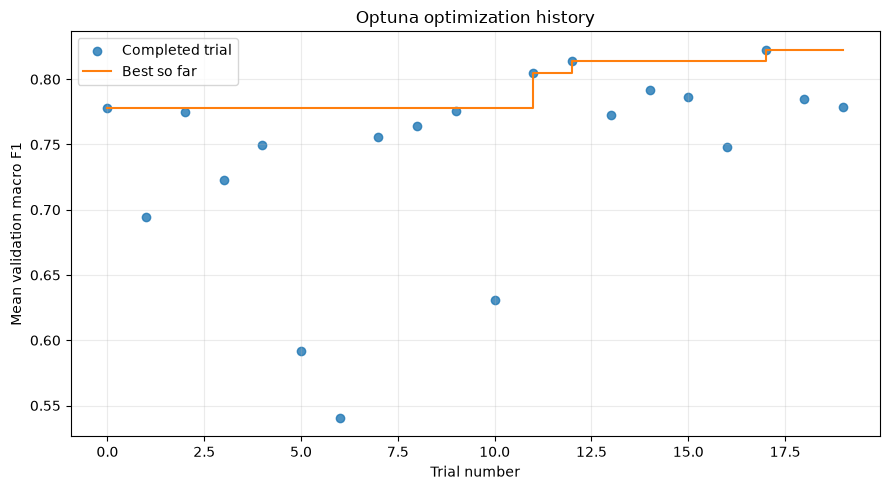

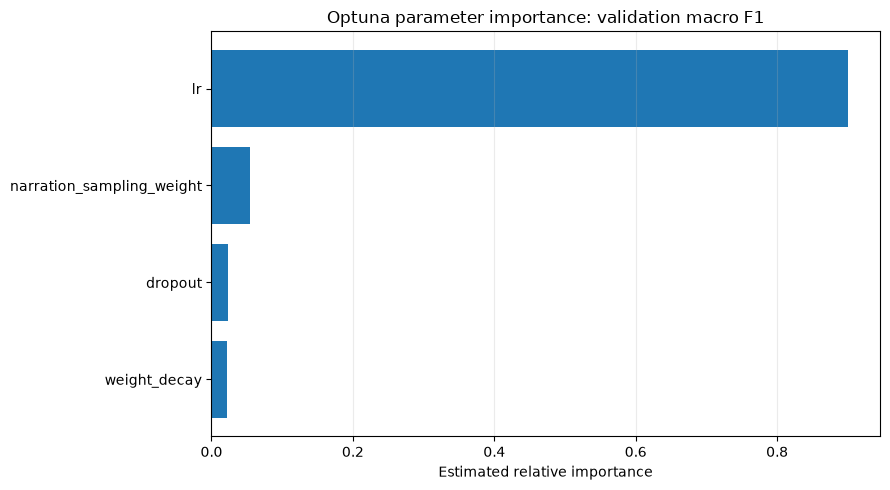

Graphs saved in: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTraining\runs\optuna_tuning\plots


In [5]:
# Cell purpose: Plot completed Optuna trials without starting or repeating training.
# Inputs: The in-memory study, or the saved SQLite study under runs/optuna_tuning.
# Outputs: Inline graphs and PNG files in the study's plots folder.

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import optuna
from config import CONFIG

# This cell can run by itself after a study has been saved.
plot_output = Path(globals().get('OUTPUT', CONFIG['run_dir'] / 'optuna_tuning'))
plot_study_name = globals().get('STUDY_NAME', 'fixed_split_macro_f1_v1')
plot_study = globals().get('study')
plot_database = plot_output / 'study.db'
if plot_study is None and plot_database.exists():
    plot_study = optuna.load_study(
        study_name=plot_study_name,
        storage='sqlite:///' + plot_database.resolve().as_posix(),
    )

completed = [] if plot_study is None else [
    trial for trial in plot_study.trials
    if trial.state == optuna.trial.TrialState.COMPLETE
    and trial.value is not None and np.isfinite(trial.value)
]
if not completed:
    print('No completed Optuna trials yet. Run the tuning cell, then rerun this plotting cell.')
else:
    plots = plot_output / 'plots'
    plots.mkdir(parents=True, exist_ok=True)
    trial_numbers = [trial.number for trial in completed]
    scores = np.array([trial.value for trial in completed])

    # Each dot is the mean validation macro F1 across the fixed search seeds.
    # The line shows the highest score found up to that trial.
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(trial_numbers, scores, label='Completed trial', alpha=0.8)
    ax.step(trial_numbers, np.maximum.accumulate(scores), where='post',
            color='tab:orange', label='Best so far')
    ax.set(xlabel='Trial number', ylabel='Mean validation macro F1',
           title='Optuna optimization history')
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(plots / 'optimization_history.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    # Importance estimates need multiple trials and changing parameter values.
    # They describe this search on this validation split, not causal effects.
    varying_parameters = [
        name for name in completed[0].params
        if all(name in trial.params for trial in completed)
        and len({trial.params[name] for trial in completed}) > 1
    ]
    if len(completed) >= 2 and varying_parameters:
        try:
            importance = optuna.importance.get_param_importances(
                plot_study,
                evaluator=optuna.importance.FanovaImportanceEvaluator(seed=42),
                params=varying_parameters,
            )
        except (ValueError, RuntimeError) as error:
            print('Parameter importance is not available for these trials:', error)
        else:
            names = list(reversed(importance))
            fig, ax = plt.subplots(figsize=(9, 5))
            ax.barh(names, [importance[name] for name in names])
            ax.set(xlabel='Estimated relative importance',
                   title='Optuna parameter importance: validation macro F1')
            ax.grid(axis='x', alpha=0.25)
            fig.tight_layout()
            fig.savefig(plots / 'parameter_importance.png', dpi=160, bbox_inches='tight')
            plt.show()
            plt.close(fig)
    else:
        print('Parameter importance needs at least two completed trials with changing parameters.')
    print('Graphs saved in:', plots)


## Export BestParamTuning
Run this cell after search or after the five-seed report. It can also run independently. It compares completed candidates from notebooks 08 and 09 by their three-seed mean macro F1 (requiring the same split and seeds), then exports the winning candidate's highest-scoring available seed checkpoint. Run again after notebook 09 finishes to refresh the overall winner. No training runs here.


In [6]:
# Cell purpose: Export the overall best completed tuning candidate and study metadata.
# Inputs: Saved studies and completed seed checkpoints from notebooks 08 and 09.
# Outputs: BestParamTuning/best.pt, model.py, parameter/metadata JSON and study snapshots.
# No training is run. Rerunning refreshes the export using the available completed studies.
from config import CONFIG
from export_best_tuning import export_best_tuning

best_export = export_best_tuning(CONFIG['run_dir'].parent)


Exported: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTraining\BestParamTuning
Winning study: fixed_split_architecture_v1 | trial: 7 | mean macro F1: 0.8390318032559261
Checkpoint seed: 42 | validation macro F1: 0.8956217162872154
